# EDA conjunto — Data4Cyber (S1–S6 + S1-alt)

Análisis exploratorio de las tablas de proceso del release, una por escenario, antes de modelar.

El recorrido: cómo se ve una fila, qué mide cada columna, si el registro es íntegro, cuántas filas son
ataque, dónde faltan datos, qué columnas no son medición, qué transformación ve el modelo y cuánto de
cada feature es reloj.

Los siete escenarios se mantienen separados: `dfs` es un diccionario `{escenario: DataFrame}` y ninguna
ventana, imputación ni estadística cruza el límite entre corridas.


## 0. Configuración y carga

Corre en Google Colab: monta Drive y lee los siete CSV desde `BASE`. Es la única celda con una ruta
absoluta; el resto del notebook no vuelve a tocar el disco.

De `src2/` se importa todo lo que se repite en más de una celda —mapas de columnas, limpieza, rango
móvil, correlaciones— para que el notebook se lea como el análisis y no como una biblioteca.


In [77]:
%matplotlib inline
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# --- helpers del EDA: src2/ vive al lado del notebook ---
sys.path.insert(0, str(Path.cwd()))
from src2.data import (mostrar_dfs, eliminar_columnas, imputar_mediana,
                       partir, tipo_de, fase_de, UNIDAD)
from src2.split import separar_variables
from src2.eda import rango_movil_escenarios, primer_ataque_sostenido, tabla_nulos
from src2.graphics import plot_ataques_benignos
from src2.eval import loso

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)

BASE = Path("/media/windows/Users/pablo/Documents/UNSA/4to/MetodosCuantitativos/TPFinal/tpfinal-colab/datasets/")

dfs = {
    #"S0":     pd.read_csv(BASE / "datasetS0.csv"),
    "S1":     pd.read_csv(BASE / "datasetS1.csv"),
    "S1-alt": pd.read_csv(BASE / "datasetS1alt.csv"),
    "S2":     pd.read_csv(BASE / "datasetS2.csv"),
    "S3":     pd.read_csv(BASE / "datasetS3.csv"),
    "S4":     pd.read_csv(BASE / "datasetS4.csv"),
    "S5":     pd.read_csv(BASE / "datasetS5.csv"),
    "S6":     pd.read_csv(BASE / "datasetS6.csv"),
}
df = pd.concat(dfs.values(), ignore_index=True)


### Cómo se ve una fila

Cinco filas de cada escenario. Alcanza para ver el orden de las columnas: primero el tiempo y la
etiqueta, después los sensores de cada equipo. `attack_active` es binaria; `attack_phase` guarda el
nombre de la etapa.


In [78]:
mostrar_dfs(dfs, 5)


=== S1 ===


,timestamp,attack_active,attack_phase,attack_phase_all,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.phase_seq,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.realtime,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,...,Profile.timestamp,Profile.total_irradiance,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.phase_seq,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.realtime,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,2026-03-06 10:49:02.510000+00:00,False,normal,normal,-0.332881,-0.257555,-0.474255,49.988049,0.100314,0.411068,0.399771,0.434722,-32.414612,1,-10.411898,-10.773335,-14.131719,90.469299,28.345638,34.930420,27.193245,17.180131,308.068573,101.483826,100.216370,106.368370,408.700775,408.817810,409.224976,236.300827,...,NaN,NaN,-0.813703,-0.813148,-0.815648,49.987865,1.023536,18.600697,18.543030,18.550619,-10367.216797,1,-3456.977783,-3443.686768,-3466.552734,7428.269531,2481.447266,2476.677002,2470.145752,8.863971e+08,12987.281250,4338.543457,4320.214844,4328.522949,403.701965,403.948517,404.038788,233.246292,232.983231,233.335754
1,2026-03-06 10:49:03.510000+00:00,False,normal,normal,-0.332881,-0.257555,-0.474255,49.988049,0.100314,0.411068,0.399771,0.434722,-32.414612,1,-10.411898,-10.773335,-14.131719,90.469299,28.345638,34.930420,27.193245,17.180131,308.068573,101.483826,100.216370,106.368370,408.700775,408.817810,409.224976,236.300827,...,NaN,NaN,-0.813703,-0.813148,-0.815648,49.987865,1.023536,18.600697,18.543030,18.550619,-10367.216797,1,-3456.977783,-3443.686768,-3466.552734,7428.269531,2481.447266,2476.677002,2470.145752,8.863971e+08,12987.281250,4338.543457,4320.214844,4328.522949,403.701965,403.948517,404.038788,233.246292,232.983231,233.335754
2,2026-03-06 10:49:04.510000+00:00,False,normal,normal,-0.332881,-0.257555,-0.474255,49.988049,0.100314,0.411068,0.399771,0.434722,-32.414612,1,-10.411898,-10.773335,-14.131719,90.469299,28.345638,34.930420,27.193245,17.180131,308.068573,101.483826,100.216370,106.368370,408.700775,408.817810,409.224976,236.300827,...,NaN,NaN,-0.813703,-0.813148,-0.815648,49.987865,1.023536,18.600697,18.543030,18.550619,-10367.216797,1,-3456.977783,-3443.686768,-3466.552734,7428.269531,2481.447266,2476.677002,2470.145752,8.863971e+08,12987.281250,4338.543457,4320.214844,4328.522949,403.701965,403.948517,404.038788,233.246292,232.983231,233.335754
3,2026-03-06 10:49:05.510000+00:00,False,normal,normal,-0.332881,-0.257555,-0.474255,49.988049,0.100314,0.411068,0.399771,0.434722,-32.414612,1,-10.411898,-10.773335,-14.131719,90.469299,28.345638,34.930420,27.193245,17.180131,308.068573,101.483826,100.216370,106.368370,408.700775,408.817810,409.224976,236.300827,...,NaN,NaN,-0.813703,-0.813148,-0.815648,49.987865,1.023536,18.600697,18.543030,18.550619,-10367.216797,1,-3456.977783,-3443.686768,-3466.552734,7428.269531,2481.447266,2476.677002,2470.145752,8.863971e+08

=== S1-alt ===


,timestamp,attack_active,attack_phase,attack_phase_all,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.phase_seq,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.realtime,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,...,Profile.timestamp,Profile.total_irradiance,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.phase_seq,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.realtime,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,2026-03-05 14:22:08.330000+00:00,False,normal,normal,-0.259700,0.260008,-0.230802,50.005424,0.111993,0.391080,0.393575,0.425378,-1.924552,1,-0.549654,1.609614,-2.984512,15.337107,4.081591,-3.653193,14.908709,17.180131,283.660004,91.616562,92.138863,99.904579,405.109619,406.373840,406.551758,234.265259,...,NaN,NaN,0.011718,-0.018026,-0.008935,50.005501,0.287292,0.965963,0.955752,0.975953,-1.664583,1,2.859485,-3.165688,-1.358381,-622.042542,-205.886154,-204.597168,-211.559189,8.863603e+08,678.595215,226.057770,223.508606,229.028824,404.915222,406.064392,405.880096,234.023102,233.856308,234.672089
1,2026-03-05 14:22:09.330000+00:00,False,normal,normal,-0.259700,0.260008,-0.230802,50.005424,0.111993,0.391080,0.393575,0.425378,-1.924552,1,-0.549654,1.609614,-2.984512,15.337107,4.081591,-3.653193,14.908709,17.180131,283.660004,91.616562,92.138863,99.904579,405.109619,406.373840,406.551758,234.265259,...,NaN,NaN,0.011718,-0.018026,-0.008935,50.005501,0.287292,0.965963,0.955752,0.975953,-1.664583,1,2.859485,-3.165688,-1.358381,-622.042542,-205.886154,-204.597168,-211.559189,8.863603e+08,678.595215,226.057770,223.508606,229.028824,404.915222,406.064392,405.880096,234.023102,233.856308,234.672089
2,2026-03-05 14:22:10.330000+00:00,False,normal,normal,-0.259700,0.260008,-0.230802,50.005424,0.111993,0.391080,0.393575,0.425378,-1.924552,1,-0.549654,1.609614,-2.984512,15.337107,4.081591,-3.653193,14.908709,17.180131,283.660004,91.616562,92.138863,99.904579,405.109619,406.373840,406.551758,234.265259,...,NaN,NaN,0.011718,-0.018026,-0.008935,50.005501,0.287292,0.965963,0.955752,0.975953,-1.664583,1,2.859485,-3.165688,-1.358381,-622.042542,-205.886154,-204.597168,-211.559189,8.863603e+08,678.595215,226.057770,223.508606,229.028824,404.915222,406.064392,405.880096,234.023102,233.856308,234.672089
3,2026-03-05 14:22:11.330000+00:00,False,normal,normal,-0.259700,0.260008,-0.230802,50.005424,0.111993,0.391080,0.393575,0.425378,-1.924552,1,-0.549654,1.609614,-2.984512,15.337107,4.081591,-3.653193,14.908709,17.180131,283.660004,91.616562,92.138863,99.904579,405.109619,406.373840,406.551758,234.265259,...,NaN,NaN,0.011718,-0.018026,-0.008935,50.005501,0.287292,0.965963,0.955752,0.975953,-1.664583,1,2.859485,-3.165688,-1.358381,-622.042542,-205.886154,-204.597168,-211.559189,8.863603e+08,678.595215,226.057770,223.508606,229.028824,404.915222,406.064392,405.880096,234.023102,233.856308,234.672089
4,2026-03-05 14:

=== S2 ===


,timestamp,attack_active,attack_phase,attack_phase_all,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.phase_seq,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.realtime,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,...,Profile.timestamp,Profile.total_irradiance,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.phase_seq,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.realtime,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,2026-03-05 15:04:32.030000+00:00,False,normal,normal,-0.517860,-0.887347,-0.993601,50.035233,0.144481,0.388406,0.358195,0.395562,-46.873985,1,-14.298635,-13.485311,-19.090040,33.833946,24.345490,7.262732,2.225725,17.180131,270.960144,92.181389,84.808769,93.969978,410.247253,410.928101,411.591492,237.388428,...,NaN,NaN,-0.905096,-0.904853,-0.907231,50.037090,0.970050,12.598598,12.610975,12.605601,-7822.463867,1,-2599.813965,-2601.708984,-2620.940918,3678.419434,1227.376099,1230.005371,1221.037964,8.863615e+08,8884.983398,2959.928223,2958.310791,2966.744385,406.355377,407.165466,407.394714,234.941086,234.582230,235.351273
1,2026-03-05 15:04:33.030000+00:00,False,normal,normal,-0.517860,-0.887347,-0.993601,50.035233,0.144481,0.388406,0.358195,0.395562,-46.873985,1,-14.298635,-13.485311,-19.090040,33.833946,24.345490,7.262732,2.225725,17.180131,270.960144,92.181389,84.808769,93.969978,410.247253,410.928101,411.591492,237.388428,...,NaN,NaN,-0.905096,-0.904853,-0.907231,50.037090,0.970050,12.598598,12.610975,12.605601,-7822.463867,1,-2599.813965,-2601.708984,-2620.940918,3678.419434,1227.376099,1230.005371,1221.037964,8.863615e+08,8884.983398,2959.928223,2958.310791,2966.744385,406.355377,407.165466,407.394714,234.941086,234.582230,235.351273
2,2026-03-05 15:04:34.030000+00:00,False,normal,normal,-0.517860,-0.887347,-0.993601,50.035233,0.144481,0.388406,0.358195,0.395562,-46.873985,1,-14.298635,-13.485311,-19.090040,33.833946,24.345490,7.262732,2.225725,17.180131,270.960144,92.181389,84.808769,93.969978,410.247253,410.928101,411.591492,237.388428,...,NaN,NaN,-0.905096,-0.904853,-0.907231,50.037090,0.970050,12.598598,12.610975,12.605601,-7822.463867,1,-2599.813965,-2601.708984,-2620.940918,3678.419434,1227.376099,1230.005371,1221.037964,8.863615e+08,8884.983398,2959.928223,2958.310791,2966.744385,406.355377,407.165466,407.394714,234.941086,234.582230,235.351273
3,2026-03-05 15:04:35.030000+00:00,False,normal,normal,-0.517860,-0.887347,-0.993601,50.035233,0.144481,0.388406,0.358195,0.395562,-46.873985,1,-14.298635,-13.485311,-19.090040,33.833946,24.345490,7.262732,2.225725,17.180131,270.960144,92.181389,84.808769,93.969978,410.247253,410.928101,411.591492,237.388428,...,NaN,NaN,-0.905096,-0.904853,-0.907231,50.037090,0.970050,12.598598,12.610975,12.605601,-7822.463867,1,-2599.813965,-2601.708984,-2620.940918,3678.419434,1227.376099,1230.005371,1221.037964,8.863615e+08,8884.983398,2959.928223,29

... (4 outputs left out)

=== S5 ===


,timestamp,attack_active,attack_phase,attack_phase_all,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.phase_seq,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.realtime,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,...,Profile.timestamp,Profile.total_irradiance,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.phase_seq,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.realtime,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,2026-03-06 15:56:00.430000+00:00,False,normal,normal,-0.153369,-0.092452,-0.474946,49.972595,0.112880,0.351595,0.337841,0.377779,-17.980625,1,-5.238884,-2.774879,-9.966863,89.530151,36.104263,34.166279,19.259613,17.180131,270.198547,90.473602,87.328629,92.396309,409.927124,410.483887,410.860321,236.959930,...,NaN,NaN,-0.869748,-0.906880,-0.906900,49.968521,1.577912,13.149112,12.390856,12.484709,-7776.449707,1,-2615.771973,-2563.477051,-2597.200684,3899.353516,1490.852295,1196.520752,1211.980469,8.864063e+08,8923.767578,3085.221191,2903.618408,2934.927490,405.878052,406.669708,406.881622,234.633423,234.335587,235.081772
1,2026-03-06 15:56:01.430000+00:00,False,normal,normal,-0.153369,-0.092452,-0.474946,49.972595,0.112880,0.351595,0.337841,0.377779,-17.980625,1,-5.238884,-2.774879,-9.966863,89.530151,36.104263,34.166279,19.259613,17.180131,270.198547,90.473602,87.328629,92.396309,409.927124,410.483887,410.860321,236.959930,...,NaN,NaN,-0.869748,-0.906880,-0.906900,49.968521,1.577912,13.149112,12.390856,12.484709,-7776.449707,1,-2615.771973,-2563.477051,-2597.200684,3899.353516,1490.852295,1196.520752,1211.980469,8.864063e+08,8923.767578,3085.221191,2903.618408,2934.927490,405.878052,406.669708,406.881622,234.633423,234.335587,235.081772
2,2026-03-06 15:56:02.430000+00:00,False,normal,normal,-0.153369,-0.092452,-0.474946,49.972595,0.112880,0.351595,0.337841,0.377779,-17.980625,1,-5.238884,-2.774879,-9.966863,89.530151,36.104263,34.166279,19.259613,17.180131,270.198547,90.473602,87.328629,92.396309,409.927124,410.483887,410.860321,236.959930,...,NaN,NaN,-0.869748,-0.906880,-0.906900,49.968521,1.577912,13.149112,12.390856,12.484709,-7776.449707,1,-2615.771973,-2563.477051,-2597.200684,3899.353516,1490.852295,1196.520752,1211.980469,8.864063e+08,8923.767578,3085.221191,2903.618408,2934.927490,405.878052,406.669708,406.881622,234.633423,234.335587,235.081772
3,2026-03-06 15:56:03.430000+00:00,False,normal,normal,-0.153369,-0.092452,-0.474946,49.972595,0.112880,0.351595,0.337841,0.377779,-17.980625,1,-5.238884,-2.774879,-9.966863,89.530151,36.104263,34.166279,19.259613,17.180131,270.198547,90.473602,87.328629,92.396309,409.927124,410.483887,410.860321,236.959930,...,NaN,NaN,-0.869748,-0.906880,-0.906900,49.968521,1.577912,13.149112,12.390856,12.484709,-7776.449707,1,-2615.771973,-2563.477051,-2597.200684,3899.353516,1490.852295,1196.520752,1211.980469,8.864063e+08,8923.767578,3085.221191,2903.6

=== S6 ===


,timestamp,attack_active,attack_phase,attack_phase_all,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.phase_seq,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.realtime,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,...,Profile.timestamp,Profile.total_irradiance,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.phase_seq,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.realtime,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,2026-03-06 13:48:00.690000+00:00,False,normal,normal,0.673807,0.669863,0.761964,49.996468,0.091451,0.405029,0.386499,0.423296,44.741913,1,17.316277,14.831735,12.593901,44.557533,18.457256,15.855508,10.244770,17.180131,288.882965,96.440773,91.743080,100.699112,411.613831,411.530640,412.449585,238.108246,...,NaN,NaN,-0.897138,-0.897510,-0.898345,49.995262,0.845426,17.987444,17.896862,17.966761,-11148.832031,1,-3720.048584,-3697.885986,-3730.897217,5494.071289,1838.845947,1823.888794,1831.336182,8.864024e+08,12634.075195,4222.404785,4191.768555,4219.901367,406.085846,406.214203,406.780334,234.741791,234.218079,234.872696
1,2026-03-06 13:48:01.690000+00:00,False,normal,normal,0.673807,0.669863,0.761964,49.996468,0.091451,0.405029,0.386499,0.423296,44.741913,1,17.316277,14.831735,12.593901,44.557533,18.457256,15.855508,10.244770,17.180131,288.882965,96.440773,91.743080,100.699112,411.613831,411.530640,412.449585,238.108246,...,NaN,NaN,-0.897138,-0.897510,-0.898345,49.995262,0.845426,17.987444,17.896862,17.966761,-11148.832031,1,-3720.048584,-3697.885986,-3730.897217,5494.071289,1838.845947,1823.888794,1831.336182,8.864024e+08,12634.075195,4222.404785,4191.768555,4219.901367,406.085846,406.214203,406.780334,234.741791,234.218079,234.872696
2,2026-03-06 13:48:02.690000+00:00,False,normal,normal,0.673807,0.669863,0.761964,49.996468,0.091451,0.405029,0.386499,0.423296,44.741913,1,17.316277,14.831735,12.593901,44.557533,18.457256,15.855508,10.244770,17.180131,288.882965,96.440773,91.743080,100.699112,411.613831,411.530640,412.449585,238.108246,...,NaN,NaN,-0.897138,-0.897510,-0.898345,49.995262,0.845426,17.987444,17.896862,17.966761,-11148.832031,1,-3720.048584,-3697.885986,-3730.897217,5494.071289,1838.845947,1823.888794,1831.336182,8.864024e+08,12634.075195,4222.404785,4191.768555,4219.901367,406.085846,406.214203,406.780334,234.741791,234.218079,234.872696
3,2026-03-06 13:48:03.690000+00:00,False,normal,normal,0.673807,0.669863,0.761964,49.996468,0.091451,0.405029,0.386499,0.423296,44.741913,1,17.316277,14.831735,12.593901,44.557533,18.457256,15.855508,10.244770,17.180131,288.882965,96.440773,91.743080,100.699112,411.613831,411.530640,412.449585,238.108246,...,NaN,NaN,-0.897138,-0.897510,-0.898345,49.995262,0.845426,17.987444,17.896862,17.966761,-11148.832031,1,-3720.048584,-3697.885986,-3730.897217,5494.071289,1838.845947,1823.888794,1831.336182,8.864024e+08,12634.075195,4222.404785,4191.76855

### Qué mide cada columna

Lo que va antes del punto es el equipo que mide; lo que sigue, la señal. Cinco medidores AC aportan 26
señales cada uno (tensiones, corrientes, potencias, factor de potencia y frecuencia); el resto es estado
de batería, perfil del escenario y la capa de anotación.

La tabla agrupa por equipo para ver de dónde sale cada feature antes de decidir qué se descarta.


In [79]:
# --- agrupación de columnas: dispositivo, tipo, fase (los mapas viven en src2.data) ---
reg = []
for c in df.columns:
    dev, sig = partir(c)
    t = tipo_de(dev, sig)
    reg.append({"columna": c, "dispositivo": dev, "señal": sig,
                "tipo": t, "unidad": UNIDAD.get(t, "?"), "fase": fase_de(sig)})
cols = pd.DataFrame(reg)

print("columnas:", len(cols), "| dispositivos:", cols.dispositivo.nunique(), "| tipos:", cols.tipo.nunique())
print("\n--- por dispositivo ---")
por_dev = (cols.groupby("dispositivo")
           .agg(columnas=("columna", "size"), tipos=("tipo", lambda s: ", ".join(sorted(set(s)))))
           .sort_values("columnas", ascending=False))
display(por_dev)


columnas: 156 | dispositivos: 10 | tipos: 15

--- por dispositivo ---


,columnas,tipos
dispositivo,,
BSS-Inverter-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Load-B-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Substation-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Load-A-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
PV-Inverter-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Profile,8,Contexto de escenario
(sin prefijo),4,Control / etiquetas
MQTT-Price-Signal,2,Señal de precio
Battery-SOC-Reference,1,SOC


## 1. Integridad del registro y de las etiquetas

Antes de analizar nada hay que saber si la serie es usable. Tres cosas, por escenario:

- **Paso temporal**: si no es constante, una ventana móvil no mide segundos.
- **Monotonía**: si `timestamp` baja en alguna fila, el orden del archivo no es el orden real.
- **Concordancia de etiquetas**: `attack_active` tiene que ser exactamente la negación de
  `attack_phase == "normal"`. Si no, hay dos definiciones de ataque en el mismo release.

Un `False` en monotonía o en concordancia invalidaría todo lo que viene después.


In [80]:
# --- una fila por escenario: paso temporal, cobertura, monotonía y concordancia etiqueta/fase ---
filas = []
for k, datos in dfs.items():
    t = pd.to_datetime(datos["timestamp"], errors="coerce")
    paso = t.diff().dt.total_seconds().dropna()
    es_normal = datos["attack_phase"].eq("normal")
    activo = datos["attack_active"].astype(bool)
    filas.append({
        "escenario": k,
        "filas": len(datos),
        "inicio": t.min(),
        "duracion_min": round((t.max() - t.min()).total_seconds() / 60, 1),
        "paso_s": paso.mode().iloc[0],
        "pasos_distintos": paso.nunique(),
        "timestamp_nulo": int(t.isna().sum()),
        "monotonico": t.is_monotonic_increasing,
        "positivos": int(activo.sum()),
        "concuerda_con_fase": bool((activo == ~es_normal).all()),
    })

auditoria = pd.DataFrame(filas).set_index("escenario")
print("auditoría del registro crudo, una fila por escenario")
display(auditoria)


auditoría del registro crudo, una fila por escenario


,filas,inicio,duracion_min,paso_s,pasos_distintos,timestamp_nulo,monotonico,positivos,concuerda_con_fase
escenario,,,,,,,,,
S1,1798,2026-03-06 10:49:02.510+00:00,29.9,1.0,1,0,True,913,True
S1-alt,1792,2026-03-05 14:22:08.330+00:00,29.9,1.0,1,0,True,910,True
S2,1768,2026-03-05 15:04:32.030+00:00,29.4,1.0,1,0,True,903,True
S3,1800,2026-03-05 16:15:00.460+00:00,30.0,1.0,1,0,True,912,True
S4,1798,2026-03-06 15:13:02.440+00:00,29.9,1.0,1,0,True,1257,True
S5,1800,2026-03-06 15:56:00.430+00:00,30.0,1.0,1,0,True,1341,True
S6,1800,2026-03-06 13:48:00.690+00:00,30.0,1.0,1,0,True,1350,True


## 2. El objetivo: ataque contra benigno

`attack_active` es la etiqueta: `True` si esa fila pertenece a un ataque, `False` si es operación
normal. El reparto no es parejo y cambia por escenario.

Importa para leer cualquier métrica de después: con 75 % de positivos, un modelo que responda "ataque"
siempre acierta el 75 % sin detectar nada. Por eso se mira recall y especificidad, no accuracy sola.


,ataque,benigno,filas
S1,913,885,1798
S1-alt,910,882,1792
S2,903,865,1768
S3,912,888,1800
S4,1257,541,1798
S5,1341,459,1800
S6,1350,450,1800


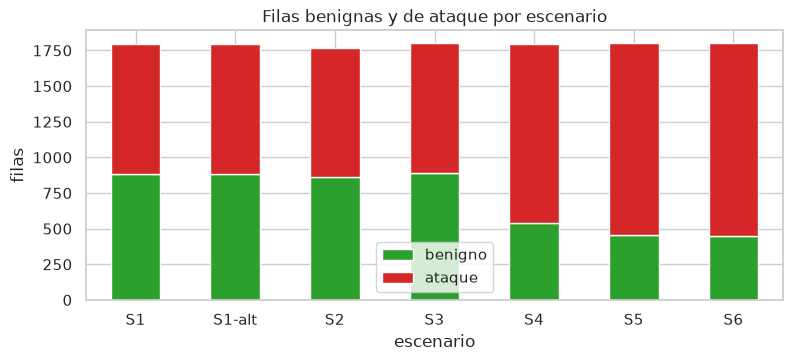

In [81]:
plot_ataques_benignos(dfs)


## 3. Datos nulos

Una celda vacía acá **no es un cero**: es ausencia de valor de origen, el medidor no reportó esa fila.
Antes de rellenar nada hay que responder dos preguntas distintas:

- **cuánto falta**: si una columna tuviera 80 % de vacíos, imputarla sería inventar la columna;
- **dónde falta**: si los vacíos están todos al principio, no es azar, es un equipo que arranca tarde.

La imputación no se hace en esta sección. Acá solo medimos y miramos el patrón; recién más adelante se
rellena, y con la mediana, que es lo que usa el pipeline supervisado.


In [82]:
# --- por escenario: cuántas columnas tienen nulos y cuál es el peor caso ---
resumen_nulos = pd.DataFrame({
    k: {
        "filas": len(datos),
        "columnas": datos.shape[1],
        "columnas_con_nulos": int(datos.isna().any().sum()),
        "peor_pct": round(100 * datos.isna().mean().max(), 2),
    }
    for k, datos in dfs.items()
}).T
print("nulos sobre las columnas crudas, un escenario por fila")
display(resumen_nulos)

# --- el escenario con más columnas afectadas, con el detalle de cada una ---
peor = resumen_nulos["columnas_con_nulos"].idxmax()
print(f"detalle de {peor}:")
display(tabla_nulos(dfs[peor]).head(10))


nulos sobre las columnas crudas, un escenario por fila


,filas,columnas,columnas_con_nulos,peor_pct
S1,1798.0,155.0,11.0,3.28
S1-alt,1792.0,155.0,11.0,1.73
S2,1768.0,155.0,11.0,1.70
S3,1800.0,155.0,11.0,1.67
S4,1798.0,155.0,143.0,2.22
S5,1800.0,155.0,11.0,1.33
S6,1800.0,156.0,12.0,24.33


detalle de S4:


,nulos,pct
MQTT-Price-Signal.price_eur_per_kwh,40,2.22
Battery-SOC-Reference.soc_value,36,2.00
BSS-Inverter-AC-Meter.cos_phi1,31,1.72
BSS-Inverter-AC-Meter.freq,31,1.72
BSS-Inverter-AC-Meter.i_sum3,31,1.72
BSS-Inverter-AC-Meter.cos_phi2,31,1.72
BSS-Inverter-AC-Meter.cos_phi3,31,1.72
BSS-Inverter-AC-Meter.iln3,31,1.72
BSS-Inverter-AC-Meter.p_sum3,31,1.72
BSS-Inverter-AC-Meter.phase_seq,31,1.72


## 4. Columnas que no son medición

Cuatro grupos salen antes de modelar, y ninguno describe el estado de la planta:

- **Etiquetas**: `attack_phase` y `attack_phase_all` son la respuesta o su detalle, no una medición.
- **Tiempo**: `timestamp` y `<equipo>.realtime`. El instante no es una medición, y `realtime` es el
  reloj interno del equipo: constante en cuatro medidores y, en la subestación, un contador.
- **Fuga**: `MQTT-Price-Signal.*`. El precio es lo que el ataque escribe en S6.
- **Perfil**: `Profile.*`. Es el guion del escenario, no una medición: S0 se grabó con el perfil
  congelado y S1–S6 con el perfil variable, así que identifica el escenario.

`attack_active` no se descarta acá: sale al separar `X` de `y`.


In [83]:
dfs = {k: eliminar_columnas(datos) for k, datos in dfs.items()}


## 5. `X` e `y`

Acá se separa la respuesta de las mediciones: `attack_active` sale de la tabla y pasa a ser `y`; el
resto es `X`. Cada escenario aporta un par `X`/`y` alineado por fila.

La validación posterior es *leave-one-scenario-out*: el modelo nunca ve el escenario que tiene que
predecir. Eso vive en el notebook de modelado; acá solo se arma el par.


In [84]:
# --- separar la respuesta de las mediciones, escenario por escenario ---
dfsX, dfsY = {}, {}
for k, datos in dfs.items():
    dfsX[k], dfsY[k] = separar_variables(datos)


### El par `X` / `y`

`X` queda con 132 columnas: los cinco medidores (26 señales cada uno) y las dos señales de batería. `y`
es una serie de booleanos del mismo largo, fila por fila. Los dos salen del mismo DataFrame, así que no
hay forma de que se desalineen.


In [85]:
mostrar_dfs(dfsX,3)
mostrar_dfs(dfsY,3)

=== S1 ===


,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,BSS-Inverter-AC-Meter.uln2,BSS-Inverter-AC-Meter.uln3,Battery-SOC-Reference.soc_value,Battery-SOC-Reported.soc_value,Load-A-AC-Meter.cos_phi1,Load-A-AC-Meter.cos_phi2,...,PV-Inverter-AC-Meter.ull31,PV-Inverter-AC-Meter.uln1,PV-Inverter-AC-Meter.uln2,PV-Inverter-AC-Meter.uln3,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,-0.332881,-0.257555,-0.474255,49.988049,0.100314,0.411068,0.399771,0.434722,-32.414612,-10.411898,-10.773335,-14.131719,90.469299,28.345638,34.93042,27.193245,308.068573,101.483826,100.21637,106.36837,408.700775,408.81781,409.224976,236.300827,235.798615,236.161591,NaN,NaN,-0.633159,0.999291,...,413.839355,239.088242,238.492233,238.838654,-0.813703,-0.813148,-0.815648,49.987865,1.023536,18.600697,18.54303,18.550619,-10367.216797,-3456.977783,-3443.686768,-3466.552734,7428.269531,2481.447266,2476.677002,2470.145752,12987.28125,4338.543457,4320.214844,4328.522949,403.701965,403.948517,404.038788,233.246292,232.983231,233.335754
1,-0.332881,-0.257555,-0.474255,49.988049,0.100314,0.411068,0.399771,0.434722,-32.414612,-10.411898,-10.773335,-14.131719,90.469299,28.345638,34.93042,27.193245,308.068573,101.483826,100.21637,106.36837,408.700775,408.81781,409.224976,236.300827,235.798615,236.161591,0.186243,NaN,-0.633159,0.999291,...,413.839355,239.088242,238.492233,238.838654,-0.813703,-0.813148,-0.815648,49.987865,1.023536,18.600697,18.54303,18.550619,-10367.216797,-3456.977783,-3443.686768,-3466.552734,7428.269531,2481.447266,2476.677002,2470.145752,12987.28125,4338.543457,4320.214844,4328.522949,403.701965,403.948517,404.038788,233.246292,232.983231,233.335754
2,-0.332881,-0.257555,-0.474255,49.988049,0.100314,0.411068,0.399771,0.434722,-32.414612,-10.411898,-10.773335,-14.131719,90.469299,28.345638,34.93042,27.193245,308.068573,101.483826,100.21637,106.36837,408.700775,408.81781,409.224976,236.300827,235.798615,236.161591,0.186243,NaN,-0.633159,0.999291,...,413.839355,239.088242,238.492233,238.838654,-0.813703,-0.813148,-0.815648,49.987865,1.023536,18.600697,18.54303,18.550619,-10367.216797,-3456.977783,-3443.686768,-3466.552734,7428.269531,2481.447266,2476.677002,2470.145752,12987.28125,4338.543457,4320.214844,4328.522949,403.701965,403.948517,404.038788,233.246292,232.983231,233.335754


=== S1-alt ===


,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,BSS-Inverter-AC-Meter.uln2,BSS-Inverter-AC-Meter.uln3,Battery-SOC-Reference.soc_value,Battery-SOC-Reported.soc_value,Load-A-AC-Meter.cos_phi1,Load-A-AC-Meter.cos_phi2,...,PV-Inverter-AC-Meter.ull31,PV-Inverter-AC-Meter.uln1,PV-Inverter-AC-Meter.uln2,PV-Inverter-AC-Meter.uln3,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,-0.2597,0.260008,-0.230802,50.005424,0.111993,0.39108,0.393575,0.425378,-1.924552,-0.549654,1.609614,-2.984512,15.337107,4.081591,-3.653193,14.908709,283.660004,91.616562,92.138863,99.904579,405.109619,406.37384,406.551758,234.265259,234.107422,234.860565,NaN,NaN,-0.662806,0.980632,...,406.408112,234.129517,234.063293,234.844894,0.011718,-0.018026,-0.008935,50.005501,0.287292,0.965963,0.955752,0.975953,-1.664583,2.859485,-3.165688,-1.358381,-622.042542,-205.886154,-204.597168,-211.559189,678.595215,226.05777,223.508606,229.028824,404.915222,406.064392,405.880096,234.023102,233.856308,234.672089
1,-0.2597,0.260008,-0.230802,50.005424,0.111993,0.39108,0.393575,0.425378,-1.924552,-0.549654,1.609614,-2.984512,15.337107,4.081591,-3.653193,14.908709,283.660004,91.616562,92.138863,99.904579,405.109619,406.37384,406.551758,234.265259,234.107422,234.860565,NaN,NaN,-0.662806,0.980632,...,406.408112,234.129517,234.063293,234.844894,0.011718,-0.018026,-0.008935,50.005501,0.287292,0.965963,0.955752,0.975953,-1.664583,2.859485,-3.165688,-1.358381,-622.042542,-205.886154,-204.597168,-211.559189,678.595215,226.05777,223.508606,229.028824,404.915222,406.064392,405.880096,234.023102,233.856308,234.672089
2,-0.2597,0.260008,-0.230802,50.005424,0.111993,0.39108,0.393575,0.425378,-1.924552,-0.549654,1.609614,-2.984512,15.337107,4.081591,-3.653193,14.908709,283.660004,91.616562,92.138863,99.904579,405.109619,406.37384,406.551758,234.265259,234.107422,234.860565,NaN,NaN,-0.662806,0.980632,...,406.408112,234.129517,234.063293,234.844894,0.011718,-0.018026,-0.008935,50.005501,0.287292,0.965963,0.955752,0.975953,-1.664583,2.859485,-3.165688,-1.358381,-622.042542,-205.886154,-204.597168,-211.559189,678.595215,226.05777,223.508606,229.028824,404.915222,406.064392,405.880096,234.023102,233.856308,234.672089


=== S2 ===


,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,BSS-Inverter-AC-Meter.uln2,BSS-Inverter-AC-Meter.uln3,Battery-SOC-Reference.soc_value,Battery-SOC-Reported.soc_value,Load-A-AC-Meter.cos_phi1,Load-A-AC-Meter.cos_phi2,...,PV-Inverter-AC-Meter.ull31,PV-Inverter-AC-Meter.uln1,PV-Inverter-AC-Meter.uln2,PV-Inverter-AC-Meter.uln3,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,-0.51786,-0.887347,-0.993601,50.035233,0.144481,0.388406,0.358195,0.395562,-46.873985,-14.298635,-13.485311,-19.09004,33.833946,24.34549,7.262732,2.225725,270.960144,92.181389,84.808769,93.969978,410.247253,410.928101,411.591492,237.388428,236.776138,237.57399,NaN,NaN,-0.68549,0.993782,...,414.998657,239.397217,238.785858,239.593597,-0.905096,-0.904853,-0.907231,50.03709,0.97005,12.598598,12.610975,12.605601,-7822.463867,-2599.813965,-2601.708984,-2620.940918,3678.419434,1227.376099,1230.005371,1221.037964,8884.983398,2959.928223,2958.310791,2966.744385,406.355377,407.165466,407.394714,234.941086,234.58223,235.351273
1,-0.51786,-0.887347,-0.993601,50.035233,0.144481,0.388406,0.358195,0.395562,-46.873985,-14.298635,-13.485311,-19.09004,33.833946,24.34549,7.262732,2.225725,270.960144,92.181389,84.808769,93.969978,410.247253,410.928101,411.591492,237.388428,236.776138,237.57399,NaN,NaN,-0.68549,0.993782,...,414.998657,239.397217,238.785858,239.593597,-0.905096,-0.904853,-0.907231,50.03709,0.97005,12.598598,12.610975,12.605601,-7822.463867,-2599.813965,-2601.708984,-2620.940918,3678.419434,1227.376099,1230.005371,1221.037964,8884.983398,2959.928223,2958.310791,2966.744385,406.355377,407.165466,407.394714,234.941086,234.58223,235.351273
2,-0.51786,-0.887347,-0.993601,50.035233,0.144481,0.388406,0.358195,0.395562,-46.873985,-14.298635,-13.485311,-19.09004,33.833946,24.34549,7.262732,2.225725,270.960144,92.181389,84.808769,93.969978,410.247253,410.928101,411.591492,237.388428,236.776138,237.57399,NaN,NaN,-0.68549,0.993782,...,414.998657,239.397217,238.785858,239.593597,-0.905096,-0.904853,-0.907231,50.03709,0.97005,12.598598,12.610975,12.605601,-7822.463867,-2599.813965,-2601.708984,-2620.940918,3678.419434,1227.376099,1230.005371,1221.037964,8884.983398,2959.928223,2958.310791,2966.744385,406.355377,407.165466,407.394714,234.941086,234.58223,235.351273


... (18 outputs left out)

=== S5 ===


0    False
1    False
2    False
Name: attack_active, dtype: bool

=== S6 ===


0    False
1    False
2    False
Name: attack_active, dtype: bool

## 6. Qué ve el modelo: rango móvil de 120 s

El modelo no ve niveles crudos, ve cuánto se movió cada señal en los últimos dos minutos. La
transformación borra el **nivel de operación**: `max(x + c) - min(x + c) = max(x) - min(x)`. La misma
señal moviéndose igual da el mismo valor en cualquier nivel, y el nivel es justo lo que cambia entre
escenarios.

Lo que **no** borra es la deriva lenta dentro de una misma corrida. Eso se mide más adelante,
correlacionando cada feature contra la posición.

La transformación es causal: cada fila usa solo su pasado, dentro de su escenario.


In [86]:
# --- rango sobre X crudo, con ventana truncada en el arranque (min_periods=1), igual que el pipeline ---
dfsR = rango_movil_escenarios(dfsX)
print("filas por escenario:", {k: len(df) for k, df in dfsR.items()})
print("columnas del rango:", next(iter(dfsR.values())).shape[1])
mostrar_dfs({"S3": dfsR["S3"]}, 8)


filas por escenario: {'S1': 1798, 'S1-alt': 1792, 'S2': 1768, 'S3': 1800, 'S4': 1798, 'S5': 1800, 'S6': 1800}
columnas del rango: 132
=== S3 ===


,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,BSS-Inverter-AC-Meter.uln2,BSS-Inverter-AC-Meter.uln3,Battery-SOC-Reference.soc_value,Battery-SOC-Reported.soc_value,Load-A-AC-Meter.cos_phi1,Load-A-AC-Meter.cos_phi2,...,PV-Inverter-AC-Meter.ull31,PV-Inverter-AC-Meter.uln1,PV-Inverter-AC-Meter.uln2,PV-Inverter-AC-Meter.uln3,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,NaN,NaN,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,NaN,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,NaN,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,NaN,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.20985,0.298274,0.415712,0.006077,0.012434,0.003391,0.008391,0.010579,22.681031,7.692233,6.579487,8.409311,5.206398,1.152031,5.040682,11.399113,1.343994,0.7911,1.977074,2.529961,0.082031,0.093109,0.090363,0.019974,0.011688,0.09024,0.0000

## 7. Imputación

Se imputa **después** de transformar. El rango móvil se calcula sobre los valores crudos y las filas
que quedan vacías al principio —ventana truncada— se rellenan al final con la mediana de la columna.
Es la misma receta del pipeline: `SimpleImputer(strategy="median")`, que en el modelo se ajusta solo
con el fold de entrenamiento.

Al revés sería peor: imputar antes de calcular el rango rellena el arranque con un valor que nunca
ocurrió, y ese valor inventado se propaga 120 s dentro de cada ventana.


In [87]:
# --- se imputa X y el rango por separado y sin recortar filas: el pipeline no descarta el arranque ---
dfsX = {k: imputar_mediana(df) for k, df in dfsX.items()}
dfsR = {k: imputar_mediana(df) for k, df in dfsR.items()}
print("nulos restantes en X:", {k: int(df.isna().sum().sum()) for k, df in dfsX.items()})
print("nulos restantes en el rango:", {k: int(df.isna().sum().sum()) for k, df in dfsR.items()})
print("filas por escenario:", {k: len(df) for k, df in dfsX.items()})

nulos restantes en X: {'S1': 0, 'S1-alt': 0, 'S2': 0, 'S3': 0, 'S4': 0, 'S5': 0, 'S6': 0}
nulos restantes en el rango: {'S1': 0, 'S1-alt': 0, 'S2': 0, 'S3': 0, 'S4': 0, 'S5': 0, 'S6': 0}
filas por escenario: {'S1': 1798, 'S1-alt': 1792, 'S2': 1768, 'S3': 1800, 'S4': 1798, 'S5': 1800, 'S6': 1800}


## 8. Nivel crudo contra rango

Una sola señal, `p_sum3` del inversor de baterías, en una ventana de 240 filas antes y 480 después del
primer ataque sostenido. Arriba el nivel crudo, abajo el rango móvil de 120 s, y en rojo la etiqueta.

La figura tiene que mostrar lo que afirma la sección 6: el nivel crudo se mueve por su cuenta y el rango
cae cuando el medidor deja de moverse. Las dos medianas impresas resumen esa caída.


rango mediana antes del ataque: 14175.6
rango mediana durante el ataque: 142.6


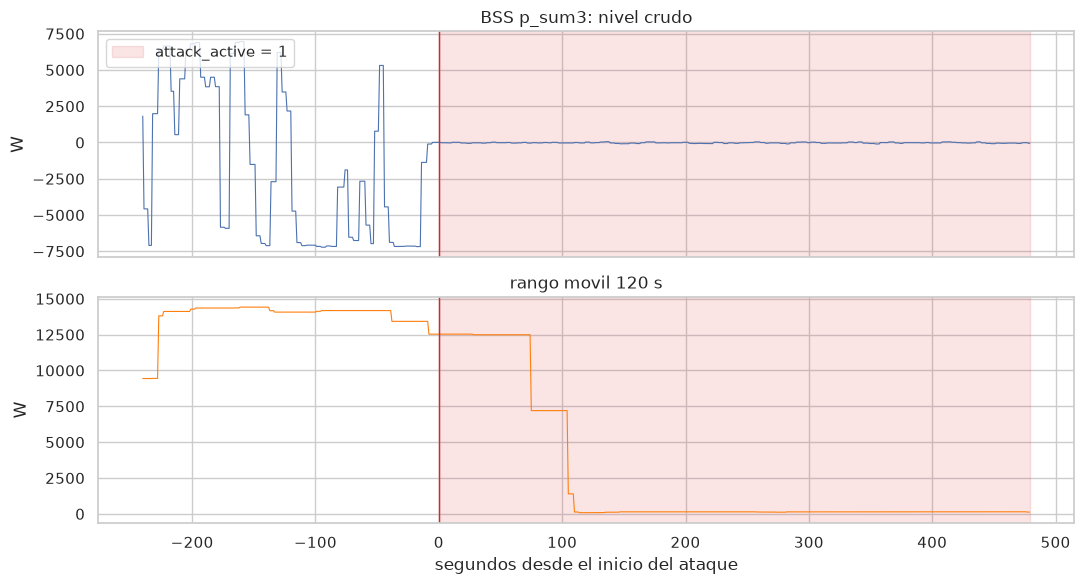

In [88]:
# --- ubica el primer ataque sostenido en S1 y compara nivel crudo contra rango movil ---

senal = "BSS-Inverter-AC-Meter.p_sum3"
escenario = "S1"

# --- series del escenario elegido: etiqueta, nivel crudo y rango movil ---
y = dfsY[escenario].to_numpy()
crudo = dfsX[escenario][senal].to_numpy()
rango = dfsR[escenario][senal].to_numpy()

inicio_rel = primer_ataque_sostenido(y)

# --- ventana de 240 filas antes y 480 despues, recortada a los limites del escenario ---
inicio = max(inicio_rel - 240, 0)
fin = min(inicio_rel + 480, len(y))
ventana = np.arange(inicio, fin)
x = ventana - inicio_rel
ataque = y[ventana] == 1

fig, ejes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ejes[0].plot(x, crudo[ventana], lw=0.8)
ejes[0].set_title("BSS p_sum3: nivel crudo")
ejes[1].plot(x, rango[ventana], lw=0.8, color="tab:orange")
ejes[1].set_title("rango movil 120 s")
ejes[1].set_xlabel("segundos desde el inicio del ataque")

# --- sombrea solo hasta la ultima fila con attack_active = 1 dentro de la ventana ---
fin_ataque = x[ataque].max() if ataque.any() else 0
for eje in ejes:
    eje.axvspan(0, fin_ataque, color="tab:red", alpha=0.12, label="attack_active = 1")
    eje.axvline(0, color="tab:red", lw=1)
    eje.set_ylabel("W")
ejes[0].legend(loc="upper left")

# --- mediana del rango antes (x < 0) y durante el ataque, en la ventana ---
antes = x < 0
print("rango mediana antes del ataque:", round(float(np.nanmedian(rango[ventana][antes])), 1))
print("rango mediana durante el ataque:", round(float(np.nanmedian(rango[ventana][ataque])), 1))

fig.tight_layout()
plt.show()


## 9. Línea base sin la transformación

Este Random Forest entrena con los **niveles crudos** de `X`, no con el rango: es la referencia contra la
que después se mide el aporte de la transformación. Un fold por escenario (leave-one-scenario-out): se
entrena con los demás y se predice el que queda afuera.

Es el único modelo del notebook. La comparación entre crudo y rango vive en el notebook de modelado; acá
solo queda el punto de partida.


In [89]:
PARAMS_RF = {
    "n_estimators": 120,
    "max_depth": 18,
    "min_samples_leaf": 2,
    "class_weight": "balanced",
    "random_state": 42,
    "n_jobs": -1,
}

# --- un fold por escenario: se entrena con los demas y se predice el que queda afuera ---
tabla_crudo, (y_true, y_pred, y_proba) = loso(dfsX, dfsY, RandomForestClassifier(**PARAMS_RF))
print("RF LOSO sobre niveles crudos")
display(tabla_crudo)

print("AUC promedio:", round(tabla_crudo["auc"].mean(), 3), "| desvio:", round(tabla_crudo["auc"].std(), 3))
print("accuracy global:", round(accuracy_score(y_true, y_pred), 3))
print("AUC global:", round(roc_auc_score(y_true, y_proba), 3))
print("matriz de confusion [[TN FP], [FN TP]]:")
print(confusion_matrix(y_true, y_pred))


RF LOSO sobre niveles crudos


,n,positivos,accuracy,precision,recall,f1,auc
escenario,,,,,,,
S1,1798,913,0.521,1.000,0.057,0.108,0.918
S1-alt,1792,910,0.750,0.670,1.000,0.802,0.796
S2,1768,903,0.607,0.674,0.446,0.537,0.723
S3,1800,912,0.788,0.756,0.860,0.805,0.850
S4,1798,1257,0.651,0.976,0.514,0.673,0.922
S5,1800,1341,0.648,0.944,0.561,0.703,0.894
S6,1800,1350,0.572,0.972,0.442,0.608,0.937


AUC promedio: 0.863 | desvio: 0.079
accuracy global: 0.648
AUC global: 0.804
matriz de confusion [[TN FP], [FN TP]]:
[[3996  974]
 [3442 4144]]


## 10. Qué pasa si no se usa LOSO

In [90]:
# --- split aleatorio: 75 % de las filas al azar, ignorando a qué escenario pertenecen ---
X_todo = pd.concat(dfsX.values(), ignore_index=True)
y_todo = pd.concat(dfsY.values(), ignore_index=True)
escenario_todo = pd.concat([pd.Series(k, index=df.index) for k, df in dfsX.items()], ignore_index=True)
posicion_todo = pd.Series(np.arange(len(X_todo)))

X_tr, X_te, y_tr, y_te, esc_tr, esc_te, pos_tr, pos_te = train_test_split(
    X_todo, y_todo, escenario_todo, posicion_todo,
    test_size=0.25, random_state=42, stratify=y_todo)

rf_azar = RandomForestClassifier(**PARAMS_RF).fit(X_tr, y_tr)
pred_azar = rf_azar.predict(X_te)
proba_azar = rf_azar.predict_proba(X_te)[:, 1]

# --- cuantas filas de test tienen a su fila anterior dentro del entrenamiento ---
en_train = set(zip(esc_tr, pos_tr))
vecina_en_train = np.mean([(e, p - 1) in en_train for e, p in zip(esc_te, pos_te)])
print(f"filas de test con su vecina temporal en train: {100 * vecina_en_train:.1f} %")

# --- el mismo modelo, las dos formas de partir ---
comparacion = pd.DataFrame({
    "split aleatorio 75/25": {
        "accuracy": accuracy_score(y_te, pred_azar),
        "precision": precision_score(y_te, pred_azar, zero_division=0),
        "recall": recall_score(y_te, pred_azar, zero_division=0),
        "auc": roc_auc_score(y_te, proba_azar),
    },
    "LOSO (7 folds)": {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "auc": roc_auc_score(y_true, y_proba),
    },
})
print("mismo modelo, distinta forma de validar")
display(comparacion.T.round(3))


filas de test con su vecina temporal en train: 74.5 %
mismo modelo, distinta forma de validar


,accuracy,precision,recall,auc
split aleatorio 75/25,0.996,0.998,0.995,1.000
LOSO (7 folds),0.648,0.810,0.546,0.804


## 11. Crudo contra rango
 Comparamos que succede al entrenar con los datos crudos y lo comparamos con el uso del rango movil


In [91]:
# --- el mismo modelo sobre el rango movil ya imputado ---
tabla_rango, (y_true_r, y_pred_r, y_proba_r) = loso(dfsR, dfsY, RandomForestClassifier(**PARAMS_RF))
print("RF LOSO sobre rango movil de 120 s")
display(tabla_rango)

# --- resumen global de las dos entradas ---
resumen_entradas = pd.DataFrame({
    "crudo": {
        "AUC global": roc_auc_score(y_true, y_proba),
        "AUC por fold (medio)": tabla_crudo["auc"].mean(),
        "AUC por fold (desvio)": tabla_crudo["auc"].std(),
        "recall por fold (medio)": tabla_crudo["recall"].mean(),
        "accuracy global": accuracy_score(y_true, y_pred),
    },
    "rango 120 s": {
        "AUC global": roc_auc_score(y_true_r, y_proba_r),
        "AUC por fold (medio)": tabla_rango["auc"].mean(),
        "AUC por fold (desvio)": tabla_rango["auc"].std(),
        "recall por fold (medio)": tabla_rango["recall"].mean(),
        "accuracy global": accuracy_score(y_true_r, y_pred_r),
    },
})
print("resumen por entrada")
display(resumen_entradas.round(3))

# --- fold por fold: donde una entrada gana y la otra pierde ---
por_fold = pd.DataFrame({
    "AUC crudo": tabla_crudo["auc"],
    "AUC rango": tabla_rango["auc"],
    "recall crudo": tabla_crudo["recall"],
    "recall rango": tabla_rango["recall"],
    "accuracy crudo": tabla_crudo["accuracy"],
    "accuracy rango": tabla_rango["accuracy"],
})
print("fold por fold")
display(por_fold)


RF LOSO sobre rango movil de 120 s


,n,positivos,accuracy,precision,recall,f1,auc
escenario,,,,,,,
S1,1798,913,0.768,0.729,0.863,0.790,0.858
S1-alt,1792,910,0.720,0.659,0.927,0.771,0.846
S2,1768,903,0.612,0.737,0.373,0.496,0.840
S3,1800,912,0.841,0.882,0.793,0.835,0.898
S4,1798,1257,0.923,0.968,0.920,0.943,0.937
S5,1800,1341,0.807,0.958,0.775,0.857,0.917
S6,1800,1350,0.738,0.852,0.787,0.819,0.855


resumen por entrada


,crudo,rango 120 s
AUC global,0.804,0.863
AUC por fold (medio),0.863,0.879
AUC por fold (desvio),0.079,0.038
recall por fold (medio),0.554,0.777
accuracy global,0.648,0.773


fold por fold


,AUC crudo,AUC rango,recall crudo,recall rango,accuracy crudo,accuracy rango
escenario,,,,,,
S1,0.918,0.858,0.057,0.863,0.521,0.768
S1-alt,0.796,0.846,1.000,0.927,0.750,0.720
S2,0.723,0.840,0.446,0.373,0.607,0.612
S3,0.850,0.898,0.860,0.793,0.788,0.841
S4,0.922,0.937,0.514,0.920,0.651,0.923
S5,0.894,0.917,0.561,0.775,0.648,0.807
S6,0.937,0.855,0.442,0.787,0.572,0.738
